In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

from scipy.sparse.linalg import svds

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
import numba

@numba.guvectorize([(numba.float32[:], numba.float32[:])], "(n)->(n)")
def rolling_percentile(trace: np.ndarray, out: np.ndarray):
    for i in range(0, trace.size - 1):
        out[i] = np.percentile(trace[i:i + 30], 5)


@numba.njit(parallel=True)
def rolling_percentile_movie(m, output):
    t, row, col = m.shape
    for i in numba.prange(row):
        for j in range(col):
            rolling_percentile(m[:, i, j], output[:, i, j])

In [2]:
sub = np.zeros(movie.shape, dtype=np.float32)
rolling_percentile_movie(movie.astype(np.float32), sub)

NameError: name 'movie' is not defined

In [ ]:
del movie

In [2]:
sub = tifffile.imread("./sub_filtered.tif")

In [3]:
from sklearn.metrics import pairwise_distances
from tqdm import tqdm

In [4]:
sub = sub[:, ::2, ::2]
sub.T.shape

(18, 19, 10000)

RFBOutputContext()

JupyterWgpuCanvas()
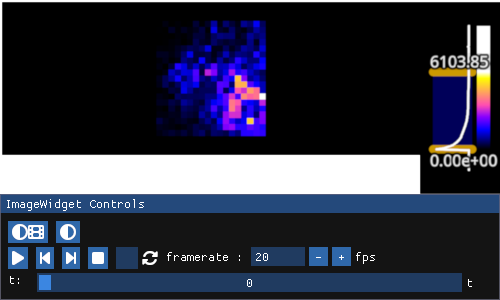

In [9]:
iw_sub = fpl.ImageWidget(sub, cmap="gnuplot2")
iw_sub.show()

In [5]:
3950-80

3870

In [6]:
Y = sub.T.reshape(sub.shape[1] * sub.shape[2], sub.shape[0])

In [7]:
Y.shape

(342, 10000)

In [8]:
from scipy.linalg import hankel

In [9]:
t = 3950
w2 = 80 * 2
w = int(w2 / 2)

snippet = Y[:, t - w:t + w:10]

print("Computing F, P")
Ys = list()
Ps = list()
Fs = list()

n_pixels = snippet.shape[0]

for i in tqdm(range(n_pixels)):
    y = hankel(Y[i, t: t + w2], Y[i, t:t + w2])
    p = np.flipud(y[:w])
    f = y[w:]

    Ps.append(p)
    Fs.append(f)

P_F_shape = (w * n_pixels, w2)

Computing F, P


100%|████████████████████████████████████████████████████████████████████| 342/342 [00:00<00:00, 27343.21it/s]


In [10]:
snippet.shape

(342, 16)

In [11]:
snippet.T.shape

(16, 342)

In [12]:
sub.shape[1] * sub.shape[2]

342

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
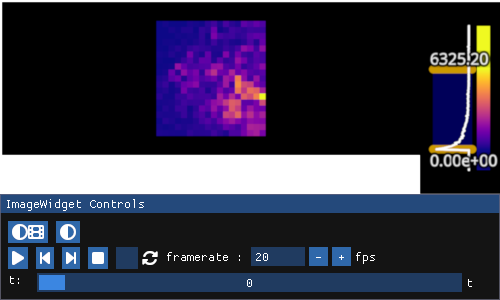

In [13]:
fpl.ImageWidget(snippet.T.reshape(snippet.shape[1], sub.shape[2], sub.shape[1]).swapaxes(1, 2)).show()

In [14]:
y.shape, p.shape, f.shape

((160, 160), (80, 160), (80, 160))

In [15]:
P_F_shape

(27360, 160)

In [16]:
P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

In [17]:
for i in tqdm(range(n_pixels)):
    P[i::n_pixels] = Ps[i]
    F[i::n_pixels] = Fs[i]

100%|████████████████████████████████████████████████████████████████████| 342/342 [00:00<00:00, 25866.49it/s]


In [18]:
print("computing H")
H = (F @ P.T) / P.shape[1] 

# H = pairwise_distances(F, P, metric="correlation", n_jobs=20)

computing H


In [19]:
H[np.isnan(H)]

array([], dtype=float64)

In [20]:
H[np.isnan(H)] = 0

In [21]:
from itertools import product

In [22]:
print("Computing Hp")
Hp = np.zeros((w ** 2, n_pixels ** 2))

for row_ix, (block_i, block_j) in enumerate(product(*[range(0, w * n_pixels, n_pixels)] * 2)):
    Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

del H

Computing Hp


In [23]:
Hp.shape

(6400, 116964)

In [24]:
from ipywidgets import HBox

In [25]:
Hp.shape

(6400, 116964)

In [26]:
w

80

In [27]:


iw_Hp = fpl.ImageWidget(Hp, cmap="viridis", histogram_widget=False)
iw_Hp_cov = fpl.ImageWidget(np.zeros((n_pixels, n_pixels)), cmap="viridis", histogram_widget=False)
iw_space = fpl.ImageWidget(np.zeros((sub.shape[2], sub.shape[1])).T, cmap="viridis", histogram_widget=False)

selector_Hp = iw_Hp.managed_graphics[0].add_linear_selector(axis="y")
selector_cov = iw_Hp_cov.managed_graphics[0].add_linear_selector(axis="y")

COV = None

@selector_Hp.add_event_handler("selection")
def update_cov(ev):
    global COV
    
    ix = ev.get_selected_index()
    COV = Hp[ix].reshape(n_pixels, n_pixels)
    iw_Hp_cov.set_data(COV)

    space = COV[selector_cov.get_selected_index()].reshape((sub.shape[2], sub.shape[1])).T
    iw_space.set_data(space)

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    space = COV[ix].reshape((sub.shape[2], sub.shape[1])).T
    iw_space.set_data(space)
    

HBox([iw_Hp.show(), iw_Hp_cov.show(), iw_space.show()])

RFBOutputContext()

RFBOutputContext()

RFBOutputContext()

In [30]:
Hp.shape

(6400, 116964)

In [42]:
Hp_std = Hp.std(axis=0).reshape(n_pixels, n_pixels)

In [44]:
Hp_std.shape

(342, 342)

In [163]:
iw_cov = fpl.ImageWidget(Hp_std.reshape(n_pixels, n_pixels), cmap="viridis")
iw_space_std = fpl.ImageWidget(np.zeros((sub.shape[2], sub.shape[1])).T, cmap="viridis", histogram_widget=False)

selector_std_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_std_cov.add_event_handler("selection")
def update_std_img(ev):
    ix = ev.get_selected_index()
    
    iw_space_std.set_data(Hp_std[ix].reshape(sub.shape[2], sub.shape[1]).T)

HBox([iw_cov.show(), iw_space_std.show()])

RFBOutputContext()

RFBOutputContext()

In [166]:
iw_space_std.reset_vmin_vmax()

In [53]:
yyt = snippet @ snippet.T

In [62]:
yyt.min(), yyt.max()

(np.float32(0.0), np.float32(687027600.0))

In [64]:
yyt -= yyt.min()
yyt /= yyt.max()

In [65]:
Hp_std.min(), Hp_std.max()

(np.float64(7.525251223083791), np.float64(1192551.2771244678))

In [66]:
Hp_std -= Hp_std.min()
Hp_std /= Hp_std.max()

In [160]:
DIFF = yyt - Hp_std

iw_cov = fpl.ImageWidget(DIFF, cmap="viridis", histogram_widget=True)
iw_space_std = fpl.ImageWidget(np.zeros((sub.shape[2], sub.shape[1])).T, cmap="viridis", histogram_widget=True)

selector_std_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_std_cov.add_event_handler("selection")
def update_std_img(ev):
    ix = ev.get_selected_index()
    global DIFF
    iw_space_std.managed_graphics[0].data = DIFF[ix].reshape(sub.shape[2], sub.shape[1]).T

HBox([iw_cov.show(), iw_space_std.show()])

RFBOutputContext()

RFBOutputContext()

In [161]:
iw_cov.cmap = "seismic"
iw_cov.managed_graphics[0].vmin, iw_cov.managed_graphics[0].vmax = -1, 1

In [162]:
iw_space_std.cmap = "seismic"
iw_space_std.managed_graphics[0].vmin, iw_space_std.managed_graphics[0].vmax = -1, 1

In [97]:
iw_space_std.reset_vmin_vmax()

In [ ]:
iw_cov = fpl.ImageWidget(Hp_std[0].reshape()

In [55]:
Hp[0].reshape(n_pixels, n_pixels).shape

(1332, 1332)

In [29]:
iw_Hp_cov.reset_vmin_vmax()
iw_space.reset_vmin_vmax()

In [38]:
COV = COV.T

RFBOutputContext()

JupyterWgpuCanvas()
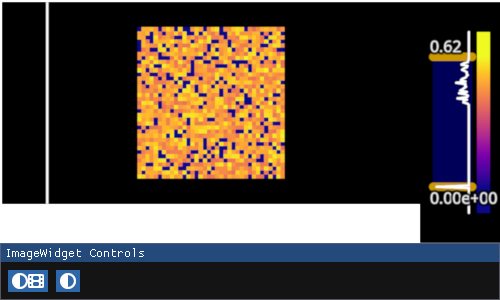

In [74]:
fpl.ImageWidget(COV.std(axis=0).reshape(sub.shape[1:])).show()

In [53]:
sub.shape

(10000, 37, 36)

In [55]:
Hp[0].reshape(n_pixels, n_pixels).shape

(1332, 1332)

In [63]:
COV.reshape(sub.shape[1:])

ValueError: cannot reshape array of size 1774224 into shape (37,36)

In [54]:
Hp[0].reshape(n_pixels, n_pixels)[0].reshape(sub.shape[1], sub.shape[2])

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
print("computimng svd of Hp")
if k is None:
    u, s, v = svd(Hp)
else:
    u, s, v = svds(Hp, k)

del Hp

self.adjacency = v[0].reshape(self.movie.shape[0], self.movie.shape[0])